## ARIMA & SARIMA

Unemployment data loaded:
           observation_date     Value
DATE                                 
1949-01-01       1949-01-01  5.255053
1949-04-01       1949-04-01  5.261516
1949-07-01       1949-07-01  5.268013
1949-10-01       1949-10-01  5.274564
1950-01-01       1950-01-01  5.281182

Milk data loaded:
            Milk
Month           
1962-01-01   589
1962-02-01   561
1962-03-01   640
1962-04-01   656
1962-05-01   727

=== Unemployment Grid Search ===
Best ARIMA for Unemployment: {'p': 3.0, 'd': 3.0, 'q': 3.0, 'RMSE': 0.0003}


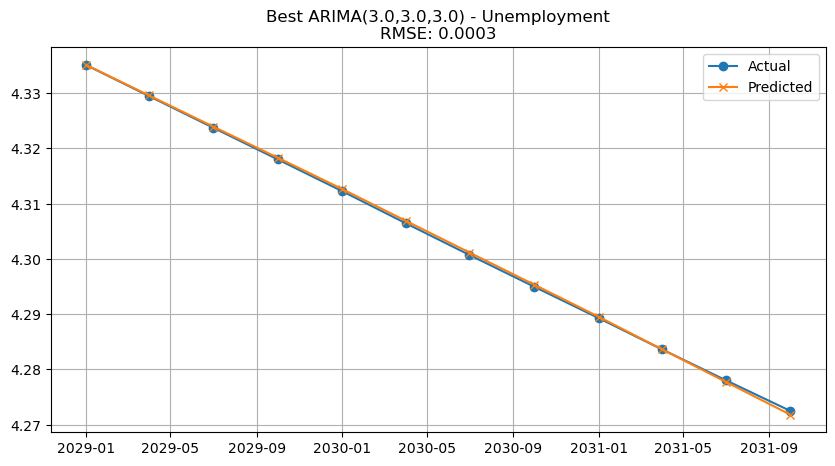


=== Milk Production Grid Search ===
Best ARIMA for Milk: {'p': 3.0, 'd': 1.0, 'q': 2.0, 'RMSE': 30.1552}


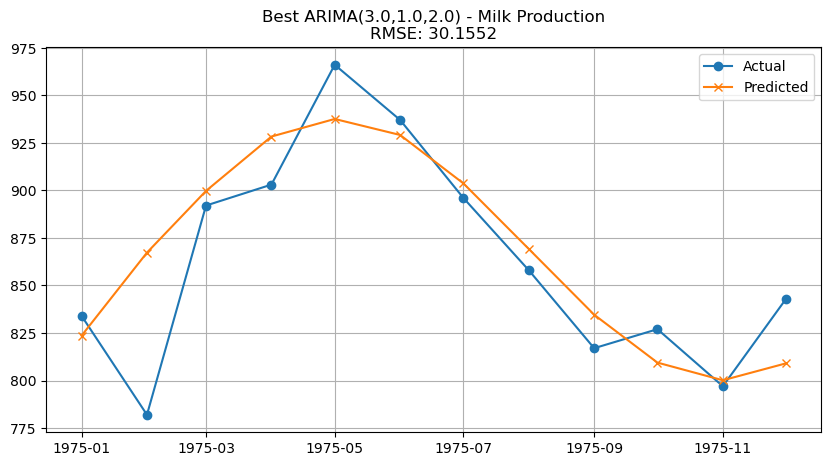


Unemployment all results:
     p  d  q    RMSE
63  3  3  3  0.0003
13  0  3  1  0.0004
58  3  2  2  0.0006
41  2  2  1  0.0007
62  3  3  2  0.0011
57  3  2  1  0.0012
31  1  3  3  0.0013
29  1  3  1  0.0013
54  3  1  2  0.0013
56  3  2  0  0.0013

Milk all results:
     p  d  q     RMSE
54  3  1  2  30.1552
53  3  1  1  45.4396
39  2  1  3  57.5798
59  3  2  3  57.9733
7   0  1  3  58.2746
23  1  1  3  58.5054
55  3  1  3  60.0141
35  2  0  3  62.2880
11  0  2  3  64.2027
46  2  3  2  65.8068


In [6]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error  # root_mean_squared_error is in newer sklearn
from statsmodels.tsa.arima.model import ARIMA

# === 1. Unemployment Rate (FRED NROUST) ===
FRED_NROUST = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=NROUST"

df_unemp = pd.read_csv(FRED_NROUST)
df_unemp['DATE'] = pd.to_datetime(df_unemp['observation_date'])
df_unemp = df_unemp.set_index('DATE')
df_unemp = df_unemp.rename(columns={'NROUST': 'Value'})  # Rename to match your code

print("Unemployment data loaded:")
print(df_unemp.head())

y_train_unemp = df_unemp['Value'][:-12]
y_test_unemp  = df_unemp['Value'][-12:]

# === 2. Milk Production ===
MILK_URL = "https://raw.githubusercontent.com/plotly/datasets/master/monthly-milk-production-pounds.csv"

df_milk = pd.read_csv(MILK_URL)
df_milk['Month'] = pd.to_datetime(df_milk['Month'])
df_milk = df_milk.set_index('Month')
df_milk = df_milk.rename(columns={'Monthly milk production (pounds per cow)': 'Milk'})

print("\nMilk data loaded:")
print(df_milk.head())

y_train_milk = df_milk['Milk'][:-12]
y_test_milk  = df_milk['Milk'][-12:]

# =====================================================================
# Function to run grid search and find best ARIMA (p,d,q in 0..3)
# =====================================================================
def find_best_arima(y_train, y_test):
    results = []
    for p in range(4):
        for d in range(4):
            for q in range(4):
                try:
                    model = ARIMA(y_train, order=(p, d, q))
                    model_fit = model.fit()
                    y_pred = model_fit.predict(start=len(y_train), end=len(y_train) + len(y_test) - 1)
                    rmse = np.sqrt(mean_squared_error(y_test, y_pred))  # or root_mean_squared_error if available
                    results.append([p, d, q, round(rmse, 4)])
                except Exception as e:
                    # Skip invalid models (e.g., convergence issues)
                    pass
    df_results = pd.DataFrame(results, columns=['p', 'd', 'q', 'RMSE'])
    best = df_results.sort_values('RMSE').iloc[0]
    return best, df_results

# =====================================================================
# Run for Unemployment
# =====================================================================
print("\n=== Unemployment Grid Search ===")
best_unemp, all_unemp = find_best_arima(y_train_unemp, y_test_unemp)
print("Best ARIMA for Unemployment:", best_unemp.to_dict())

# Plot best
model = ARIMA(y_train_unemp, order=(best_unemp.p, best_unemp.d, best_unemp.q))
model_fit = model.fit()
y_pred_unemp = model_fit.predict(start=len(y_train_unemp), end=len(y_train_unemp) + len(y_test_unemp) - 1)

plt.figure(figsize=(10, 5))
plt.plot(y_test_unemp.index, y_test_unemp, label='Actual', marker='o')
plt.plot(y_pred_unemp.index, y_pred_unemp, label='Predicted', marker='x')
plt.title(f"Best ARIMA({best_unemp.p},{best_unemp.d},{best_unemp.q}) - Unemployment\nRMSE: {best_unemp.RMSE}")
plt.legend()
plt.grid(True)
plt.show()

# =====================================================================
# Run for Milk
# =====================================================================
print("\n=== Milk Production Grid Search ===")
best_milk, all_milk = find_best_arima(y_train_milk, y_test_milk)
print("Best ARIMA for Milk:", best_milk.to_dict())

# Plot best
model = ARIMA(y_train_milk, order=(best_milk.p, best_milk.d, best_milk.q))
model_fit = model.fit()
y_pred_milk = model_fit.predict(start=len(y_train_milk), end=len(y_train_milk) + len(y_test_milk) - 1)

plt.figure(figsize=(10, 5))
plt.plot(y_test_milk.index, y_test_milk, label='Actual', marker='o')
plt.plot(y_pred_milk.index, y_pred_milk, label='Predicted', marker='x')
plt.title(f"Best ARIMA({best_milk.p},{best_milk.d},{best_milk.q}) - Milk Production\nRMSE: {best_milk.RMSE}")
plt.legend()
plt.grid(True)
plt.show()

# Optional: full results tables
print("\nUnemployment all results:\n", all_unemp.sort_values('RMSE').head(10))
print("\nMilk all results:\n", all_milk.sort_values('RMSE').head(10))

In [5]:
df_unemp.columns

Index(['observation_date', 'NROUST'], dtype='object')

In [ ]:
os.chdir('AirP')

In [ ]:
model = ARIMA(y)